In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import scipy.stats as stats
from collections import defaultdict

In [2]:
df_bg_list = []
for f in os.listdir('../Background_gloves'):
    df = pd.read_csv('../Background_gloves/'+f)
    df = df.set_index('X value [cm⁻¹]').T
    df = df.reset_index(drop=True)
    df.insert(0, 'id', [f[27:] + '_' + str(i) for i in range(df.shape[0])])
    df_bg_list.append(df)
    
df_bg = pd.concat(df_bg_list, axis=0).reset_index(drop=True)
df_bg['background'] = 1

df_nbg_list = []
for f in os.listdir('../Non-Background_gloves'):
    df = pd.read_csv('../Non-Background_gloves/'+f)
    df = df.set_index('X value [cm⁻¹]').T
    df = df.reset_index(drop=True)
    df.insert(0, 'id', [f[27:] + '_' + str(i) for i in range(df.shape[0])])
    df_nbg_list.append(df)
    
df_nbg = pd.concat(df_nbg_list, axis=0).reset_index(drop=True)
df_nbg['background'] = 0

In [3]:
df_all = pd.concat([df_bg, df_nbg], axis=0).reset_index(drop=1)
df_all = df_all.loc[np.isnan(df_all.iloc[:,1:-1]).sum(1)==0,:]
x, y = np.array(df_all.iloc[:,1:-1]), np.float64(df_all.iloc[:,-1])

wn_bg = np.array(df_all.columns[1:-1])

idx_bg = np.logical_or(np.logical_and(wn_bg > 980, wn_bg < 1800),
np.logical_and(wn_bg > 2720, wn_bg < 2980) #2993.64990234375-10
) 
x = x[:,idx_bg]
x_norm = (x - x.mean(1)[:,None]) / x.std(1)[:,None]

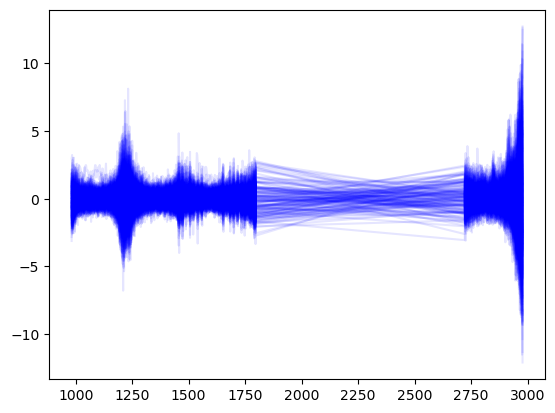

In [4]:
_ = plt.plot(wn_bg[idx_bg],
         x_norm[y==1].T, c ='b',alpha=.1)

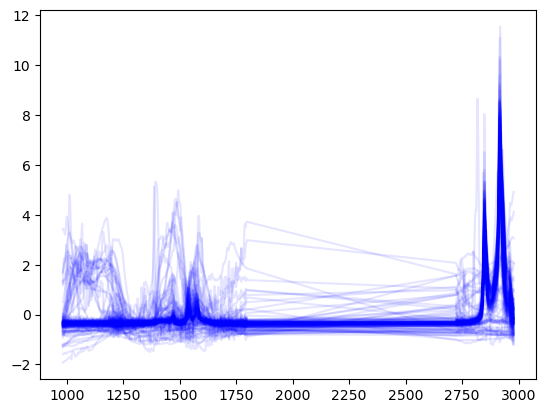

In [5]:
_ = plt.plot(wn_bg[idx_bg],
         x_norm[y==0].T, c ='b',alpha=.1)

In [6]:
1-stats.norm.cdf(4)

3.167124183311998e-05

In [7]:
quant_table = pd.DataFrame(np.array([[np.round(1-alpha,4), np.round(stats.norm.ppf(1-alpha),2)] for alpha in [0.0013498980316301035, .01,.03,.05,.07,.1,.15,.20,.25]]))
quant_table.columns = ['1-alpha','quantile']
quant_table

,1-alpha,quantile
0,0.9987,3.00
1,0.9900,2.33
2,0.9700,1.88
3,0.9500,1.64
4,0.9300,1.48
5,0.9000,1.28
6,0.8500,1.04
7,0.8000,0.84
8,0.7500,0.67


In [8]:

#alpha = .01
res_list = defaultdict(list)
for alpha in [.01,.03,.05,.07,.1,.15,.20,.25]:
    false_pos_list = defaultdict(list)
    false_neg_list = defaultdict(list)
    acc_list = defaultdict(list)
    n_bg_list = defaultdict(list)

    for i in range(500):
        np.random.seed(i)
        idx_train = np.random.rand(x.shape[0]) > .2

        x_train = x_norm[idx_train,:]
        y_train = y[idx_train]

        x_test = x_norm[~idx_train,:]
        y_test = y[~idx_train]

        #[np.quantile(np.mean(np.abs(np.diff(x_train[y_train==1],1)), 1), alpha) for alpha in [0,.01,.03,.05,.07,.1,.15,.20,.25]] 
        thrshold_total = np.quantile(np.mean(np.abs(np.diff(x_train[y_train==1],1)), 1), alpha) 
        y_test_hat_total = (np.mean(np.abs(np.diff(x_test,1)), 1) > thrshold_total)*1
        pos_idx = y_test_hat_total==1
        neg_idx = y_test_hat_total==0

        false_pos, false_neg, acc = (np.mean(y_test[pos_idx] == 0),
                                     np.mean(y_test[neg_idx] == 1),
                                     np.mean(y_test_hat_total == y_test))

        #print(false_pos, false_neg)

        false_pos_list['total_var'].append(false_pos)
        false_neg_list['total_var'].append(false_neg)
        acc_list['total_var'].append(acc)
        n_bg_list['total_var'].append(y_test_hat_total.mean())

        x_train = x[idx_train,:]
        x_test = x[~idx_train,:]

        thrshold_mean_int = np.quantile(np.mean(x_train[y_train==1], 1), 1-alpha) 
        y_test_hat_mean_int = (np.mean(x_test, 1) < thrshold_mean_int)*1
        pos_idx = y_test_hat_mean_int==1
        neg_idx = y_test_hat_mean_int==0

        false_pos, false_neg, acc = (np.mean(y_test[pos_idx] == 0),
                                np.mean(y_test[neg_idx] == 1),
                                np.mean(y_test_hat_mean_int == y_test))
        #print(false_pos, false_neg)
        false_pos_list['mean_int'].append(false_pos)
        false_neg_list['mean_int'].append(false_neg)
        acc_list['mean_int'].append(acc)
        n_bg_list['mean_int'].append(y_test_hat_mean_int.mean())

        thrshold_mean_int_norm = np.mean(x_train[y_train==1], 1).mean() + np.mean(x_train[y_train==1], 1).std()*stats.norm.ppf(1-alpha)
        y_test_hat_mean_int_norm = (np.mean(x_test, 1) < thrshold_mean_int_norm)*1
        pos_idx = y_test_hat_mean_int_norm==1
        neg_idx = y_test_hat_mean_int_norm==0

        false_pos, false_neg, acc = (np.mean(y_test[pos_idx] == 0),
                                np.mean(y_test[neg_idx] == 1),
                                np.mean(y_test_hat_mean_int_norm == y_test))

        #print(false_pos, false_neg)
        false_pos_list['mean_int_norm'].append(false_pos)
        false_neg_list['mean_int_norm'].append(false_neg)
        acc_list['mean_int_norm'].append(acc)
        n_bg_list['mean_int_norm'].append(y_test_hat_mean_int_norm.mean())
    
    df = pd.DataFrame(pd.DataFrame(false_pos_list).mean())
    df.columns = [str(int(alpha*100))]
    df = df.T
    res_list['false_pos'].append(df)
    
    df = pd.DataFrame(pd.DataFrame(false_neg_list).mean())
    df.columns = [str(int(alpha*100))]
    df = df.T
    res_list['false_neg'].append(df)
    
    df = pd.DataFrame(pd.DataFrame(acc_list).mean())
    df.columns = [str(int(alpha*100))]
    df = df.T
    res_list['acc'].append(df)
    
    df = pd.DataFrame(pd.DataFrame(n_bg_list).mean())
    df.columns = [str(int(alpha*100))]
    df = df.T
    res_list['n'].append(df)
    

In [9]:
pd.concat(res_list['false_pos'],axis=0)#.to_csv('excl_rule_false_pos.csv')

,total_var,mean_int,mean_int_norm
1,0.0,0.006316,0.007500
3,0.0,0.000000,0.000374
5,0.0,0.000000,0.000000
7,0.0,0.000000,0.000000
10,0.0,0.000000,0.000000
15,0.0,0.000000,0.000000
20,0.0,0.000000,0.000000
25,0.0,0.000000,0.000000


In [10]:
pd.concat(res_list['false_neg'],axis=0)#.to_csv('excl_rule_false_neg.csv')

,total_var,mean_int,mean_int_norm
1,0.017304,0.017234,0.017863
3,0.037788,0.038476,0.035907
5,0.053140,0.055056,0.048896
7,0.071778,0.074632,0.057551
10,0.096016,0.099155,0.082995
15,0.132603,0.136858,0.117632
20,0.168655,0.171634,0.167831
25,0.202974,0.203679,0.193172


In [11]:
pd.concat(res_list['n'],axis=0)#.to_csv('excl_rule_background_prop.csv')

,total_var,mean_int,mean_int_norm
1,0.490942,0.494018,0.494359
3,0.479821,0.479395,0.481113
5,0.471118,0.469960,0.473839
7,0.460319,0.458575,0.468870
10,0.445643,0.443711,0.453822
15,0.422159,0.419215,0.432154
20,0.396803,0.394453,0.397691
25,0.370838,0.370375,0.379011


In [12]:
pd.concat(res_list['acc'],axis=0)#.to_csv('excl_rule_accurary.csv')

,total_var,mean_int,mean_int_norm
1,0.991111,0.987933,0.987081
3,0.979991,0.979564,0.980890
5,0.971288,0.970130,0.974009
7,0.960489,0.958745,0.969040
10,0.945813,0.943881,0.953992
15,0.922329,0.919385,0.932324
20,0.896972,0.894622,0.897860
25,0.871008,0.870545,0.879181
